# Clinical indices - evidence for the definitions of layer 3

Preprocessing (notebook 05) and PEEP trial segmentation (notebook 06) give, for every recording, the breaths, the
lung mask, the regions and, for a PEEP trial, the breaths analysed in each step with their driving pressure and tidal
volume. This notebook tests how the clinical indices are computed from them (layer 3, `fasteit.features`): every
section has a question, the method tested, the result and the decision, with the fastEIT function that implements it
(summary table at the end).

Scope of this first version:

- **each breath**: EELI, TIV (global and regional), share of ventilation by region, global inhomogeneity (GI), centre
  of ventilation (ventro-dorsal and right-left), compliance (global and regional);
- **each PEEP step**: the same indices on the analysed breaths, and the changes between steps of EELI, compliance,
  collapse and overdistension (Costa method), in a form comparable between patients;
- not included: silent spaces, regional ventilation delay, oesophageal and transpulmonary pressure. Strain is not
  possible with EIT alone: it needs an absolute end-expiratory lung volume.

| § | Question |
|---|----------|
| 1 | How are EELI and TIV of a breath read? |
| 2 | How is the distribution of ventilation described? |
| 3 | How is compliance computed, globally and by region? |
| 4 | PEEP trials: changes between steps and the Costa method |
| 5 | Decisions |

The recordings are not in the repository. EIT values are in arbitrary units; pressures in cmH2O (`preprocess()`
converts the Dräger mbar, 1 mbar = 1.02 cmH2O), volumes in mL.

*Research use only - not a medical device.*

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fasteit.models import RecordingContext
from fasteit.parsers.loader import load_data
from fasteit.preprocessing import preprocess
from fasteit.segmentation import segment_peep_trial

TEST_FILES = Path("../src/fasteit/test_files")
TIDAL_FILES = sorted(p for p in TEST_FILES.glob("*.bin") if "PEEP_trial" not in p.name)
TRIAL_FILES = sorted(TEST_FILES.glob("*PEEP_trial*.bin"))
SET_VT = {"A": 550, "B": 400}  # mL, set in volume control, the same in every step

BLUE, ORANGE, GREEN, GREY, INK = "#3987e5", "#e8730c", "#2a9d6f", "#9a9a9a", "#2b2b2b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "font.size": 9})

tidal = {p.stem: preprocess(load_data(p)) for p in TIDAL_FILES}
trials = {}
for p in TRIAL_FILES:
    name = p.stem.replace("PEEP_trial_", "")
    context = RecordingContext(protocol="peep_trial", tidal_volume_ml=SET_VT[name[0]])
    trials[name] = segment_peep_trial(preprocess(load_data(p), context=context))
print(len(tidal), "tidal recordings,", len(trials), "PEEP trials")

11 tidal recordings, 4 PEEP trials


## 1. How are EELI and TIV of a breath read?

Following TREND (Frerichs et al., Thorax 2017, DOI: 10.1136/thoraxjnl-2016-208357), on the global signal inside the
lung mask:

- **EELI** = the signal at the end-expiratory valley at the **start** of the breath (the end of the previous
  expiration), the same moment as the PEEP of the breath (notebook 06). eitprocessing takes the valley at the end of
  the breath, i.e. the start of the next one.
- **TIV** = the signal at the peak minus the signal at the start of the breath (the "inspiratory" TIV, the default of
  eitprocessing).

First check: on the breaths that eitprocessing (v1.8.8, `EELI`, `TIV`) finds identical to fastEIT, the values must be
the same.

In [2]:
def level_at(values, frames, fs, half_seconds):
    """Mean of `values` (time on axis 0) in +/- half_seconds around each frame (one sample if 0)."""
    h = int(round(half_seconds * fs))
    return np.array([values[max(0, f - h) : f + h + 1].mean(axis=0) for f in frames])


def eeli_tiv(rec, half_seconds):
    b = rec.breaths
    start = level_at(rec.global_signal, b.start_idx.to_numpy(), rec.fs, half_seconds)
    peak = level_at(rec.global_signal, b.peak_idx.to_numpy(), rec.fs, half_seconds)
    end = level_at(rec.global_signal, b.end_idx.to_numpy(), rec.fs, half_seconds)
    return pd.DataFrame({"eeli_start": start, "eeli_end": end, "tiv": peak - start})

In [3]:
from eitprocessing.datahandling.continuousdata import ContinuousData
from eitprocessing.features.breath_detection import BreathDetection
from eitprocessing.parameters.eeli import EELI
from eitprocessing.parameters.tidal_impedance_variation import TIV

rows = []
for name, rec in list(tidal.items()) + [(n, t.recording) for n, t in trials.items()]:
    signal = ContinuousData(label="global", name="global", unit="a.u.", category="impedance",
                            time=np.asarray(rec.time), values=np.asarray(rec.global_signal), sample_frequency=rec.fs)
    ref_eeli = EELI().compute_parameter(signal)
    ref_tiv = TIV().compute_continuous_parameter(signal, tiv_method="inspiratory")
    ours = eeli_tiv(rec, 0.0)
    b = rec.breaths
    # eitprocessing finds its own breaths on this signal: compare the breaths with the same start, peak and end
    theirs = {(round(x.start_time, 3), round(x.middle_time, 3), round(x.end_time, 3)): i
              for i, x in enumerate(BreathDetection().find_breaths(signal).values)}
    eeli_by_end = dict(zip(np.round(ref_eeli.time, 3), ref_eeli.values))
    diffs, same = [], 0
    for i, key in enumerate(zip(np.round(b.start_time, 3), np.round(b.peak_time, 3), np.round(b.end_time, 3))):
        if key in theirs:
            same += 1
            diffs += [abs(ref_tiv.values[theirs[key]] - ours.tiv[i]), abs(eeli_by_end[key[2]] - ours.eeli_end[i])]
    rows.append({"recording": name, "breaths": len(b), "same breaths": same,
                 "max difference": max(diffs) if diffs else np.nan})
pd.DataFrame(rows).set_index("recording")

,breaths,same breaths,max difference
recording,,,
01_Healthy_Lung_01,9,8,0.0
patient01_rec02,14,7,0.0
patient01_rec03,55,29,0.0
patient01_rec04,117,53,0.0
patient01_rec05,104,76,0.0
patient01_rec07,100,73,0.0
patient01_rec09,68,26,0.0
patient01_rec11,89,16,0.0
patient01_rec12,88,42,0.0


**Result:** where the breaths are the same the values are identical. Often they are not the same: eitprocessing
searches the valleys and peaks on the signal inside the lung mask, fastEIT on the sum of all pixels (the mask needs
the breaths, notebook 05). To measure how much the timing matters for the TIV inside the mask, each valley and peak is
moved to the extremum of the in-mask signal within 0.3 s:

In [4]:
rows = []
for name, rec in list(tidal.items()) + [(n, t.recording) for n, t in trials.items()]:
    g, fs = np.asarray(rec.global_signal), rec.fs
    b = rec.breaths[rec.breaths.is_valid]
    w = int(round(0.3 * fs))
    s, p = b.start_idx.to_numpy(), b.peak_idx.to_numpy()
    s_own = np.array([max(0, x - w) + np.argmin(g[max(0, x - w) : x + w + 1]) for x in s])
    p_own = np.array([max(0, x - w) + np.argmax(g[max(0, x - w) : x + w + 1]) for x in p])
    ratio = (g[p] - g[s]) / (g[p_own] - g[s_own]) - 1
    rows.append({"recording": name, "valley shift (frames, max)": np.abs(s_own - s).max(),
                 "TIV difference (%, median)": 100 * np.median(ratio), "TIV difference (%, worst)": 100 * ratio.min()})
pd.DataFrame(rows).set_index("recording").round(2)

,"valley shift (frames, max)","TIV difference (%, median)","TIV difference (%, worst)"
recording,,,
01_Healthy_Lung_01,0,0.00,-0.02
patient01_rec02,2,0.00,-0.14
patient01_rec03,5,0.00,-1.82
patient01_rec04,3,0.00,-1.71
patient01_rec05,2,0.00,-0.09
patient01_rec07,1,0.00,-0.03
patient01_rec09,2,0.00,-2.27
patient01_rec11,3,-0.05,-0.41
patient01_rec12,2,0.00,-1.20


**Result:** the valleys move by 0-5 frames, and the TIV with the fastEIT timing differs by 0 to -0.4 % in median
(worst breath -2.3 %).

**Decision:** every index uses the breath timing of layer 2.

One sample or a short mean? A mean of 0.2 s around start and peak would keep a cardiac oscillation from falling on a
single sample:

In [5]:
def variability(values):
    """Median breath-to-breath change, as % of the median value."""
    return 100 * np.median(np.abs(np.diff(values))) / np.median(np.abs(values))


rows = []
for name, rec in tidal.items():
    valid = rec.breaths.is_valid.to_numpy()
    one, window = eeli_tiv(rec, 0.0)[valid], eeli_tiv(rec, 0.1)[valid]
    rows.append({"recording": name,
                 "TIV, one sample": variability(one.tiv), "TIV, 0.2 s": variability(window.tiv),
                 "mean TIV difference (%)": 100 * (window.tiv.mean() / one.tiv.mean() - 1)})
pd.DataFrame(rows).set_index("recording").round(2).rename_axis("breath-to-breath change (% of median)", axis=1)

breath-to-breath change (% of median),"TIV, one sample","TIV, 0.2 s",mean TIV difference (%)
recording,,,
01_Healthy_Lung_01,9.83,9.83,-0.49
patient01_rec02,13.81,14.33,-2.00
patient01_rec03,9.21,9.12,-2.07
patient01_rec04,4.40,4.32,-2.33
patient01_rec05,8.14,8.03,-1.80
patient01_rec07,9.49,9.37,-2.07
patient01_rec09,8.38,8.05,-2.05
patient01_rec11,8.65,9.02,-2.60
patient01_rec12,10.66,11.00,-3.89


**Result:** the mean does not make the TIV more stable from breath to breath, but lowers it by 0.5-3.9 %: averaging
around a peak lowers the peak, averaging around a valley raises the valley. The cardiac component is small in these
Dräger exports (notebook 05).

**Decision:** one sample, as TREND and eitprocessing.

## 2. How is the distribution of ventilation described?

All from the **tidal image** of each breath: each pixel at the peak minus at the start, inside the lung mask
(`fasteit.features.breath_indices.tidal_images`).

- **Share by region**: TIV of the region / TIV of the lung, as a ratio of sums (a mean of pixel ratios explodes for
  pixels near zero). Regions of notebook 05: ventral/dorsal halves and layers on the lung, right/left halves.
- **GI** (Zhao et al., Intensive Care Med 2009, DOI: 10.1007/s00134-009-1589-y): sum of |pixel - median| / sum of
  pixels, over the lung pixels.
- **Centre of ventilation** (Frerichs et al., Am J Respir Crit Care Med 2006, DOI: 10.1164/rccm.200512-1942OC):
  TIV-weighted mean row (and column), divided by the last row (column), on the **image grid**, not on the regions of
  the lung, so that a shift of ventilation is not hidden (notebook 05). Ventro-dorsal: 0 = ventral, 1 = dorsal.
  Right-left: **0 = patient right, 1 = patient left** (image seen from the feet).

Check on synthetic tidal images with a known answer: homogeneous, three times more ventilation in the dorsal half,
three times more in the patient's right lung.

In [6]:
def tidal_images(rec):
    """Pixel TIV of each breath: (n_breaths, rows, cols), NaN outside the lung mask."""
    b = rec.breaths
    images = (rec.pixels[b.peak_idx.to_numpy()] - rec.pixels[b.start_idx.to_numpy()]).astype(float)
    images[:, ~rec.lung_mask] = np.nan
    return images


def gi(image):
    """Global inhomogeneity index (Zhao 2009) of one tidal image (lung pixels only)."""
    lung = image[~np.isnan(image)]
    return np.abs(lung - np.median(lung)).sum() / lung.sum()


def centre_of_ventilation(image):
    """(ventro-dorsal, right-left): 0 = ventral / patient right, 1 = dorsal / patient left."""
    tiv = np.nan_to_num(image)
    rows, cols = np.indices(tiv.shape)
    return ((tiv * rows).sum() / tiv.sum() / (tiv.shape[0] - 1),
            (tiv * cols).sum() / tiv.sum() / (tiv.shape[1] - 1))


def share(image, region):
    """% of the tidal ventilation in a region: ratio of the sums."""
    tiv = np.nan_to_num(image)
    return 100 * tiv[region].sum() / tiv.sum()


# Synthetic checks with a known answer.
flat = np.full((32, 32), np.nan)
flat[8:24, 4:28] = 1.0                              # homogeneous ventilation
dorsal = flat.copy()
dorsal[16:24, 4:28] = 3.0                           # three times more ventilation in the dorsal half
right = flat.copy()
right[8:24, 4:16] *= 3.0                            # three times more in the patient's right lung (image left)
pd.DataFrame({name: {"GI": gi(img), "CoV ventro-dorsal": centre_of_ventilation(img)[0],
                     "CoV right-left": centre_of_ventilation(img)[1]}
              for name, img in [("homogeneous", flat), ("dorsal x3", dorsal), ("right x3", right)]}).T.round(3)

,GI,CoV ventro-dorsal,CoV right-left
homogeneous,0.0,0.500,0.500
dorsal x3,0.5,0.565,0.500
right x3,0.5,0.500,0.403


**Result:** homogeneous ventilation gives GI = 0 and the centre in the middle (0.5, 0.5); more dorsal ventilation
moves the ventro-dorsal centre towards 1, more ventilation in the patient's right lung moves the right-left centre
towards 0. On the tidal recordings (median of the valid breaths):

In [7]:
def breath_indices(rec):
    rows = []
    for image in tidal_images(rec):
        vd, rl = centre_of_ventilation(image)
        rows.append({"gi": gi(image), "cov_vd": vd, "cov_rl": rl,
                     **{f"share_{r}": share(image, rec.roi_masks[r]) for r in ("ventral", "dorsal", "right", "left")}})
    return pd.DataFrame(rows)


distribution = pd.DataFrame({name: breath_indices(rec)[rec.breaths.is_valid.to_numpy()].median()
                             for name, rec in tidal.items()}).T
distribution.round(3)

,gi,cov_vd,cov_rl,share_ventral,share_dorsal,share_right,share_left
01_Healthy_Lung_01,0.381,0.502,0.465,56.366,43.634,56.578,43.422
patient01_rec02,0.388,0.449,0.489,44.044,55.956,52.553,47.447
patient01_rec03,0.439,0.474,0.497,36.428,63.572,50.862,49.138
patient01_rec04,0.431,0.487,0.480,40.701,59.299,55.137,44.863
patient01_rec05,0.371,0.445,0.486,44.607,55.393,52.353,47.647
patient01_rec07,0.358,0.438,0.467,46.631,53.369,56.780,43.220
patient01_rec09,0.447,0.488,0.480,39.668,60.332,55.126,44.874
patient01_rec11,0.483,0.532,0.504,51.253,48.747,48.337,51.663
patient01_rec12,0.532,0.527,0.506,53.226,46.774,48.246,51.754
patient01_rec13,0.529,0.514,0.498,46.832,53.168,51.175,48.825


**Result:** GI 0.36-0.53, ventro-dorsal centre 0.44-0.57, right-left centre 0.47-0.51, ventral share 36-56 %, right
share 48-57 %: no recording stands out. eitprocessing has no GI or centre of ventilation to compare with, so these
indices rest on their published formulas and on the synthetic checks.

**Decision:** GI and centre of ventilation of each breath (`breath_indices.global_inhomogeneity`,
`breath_indices.centre_of_ventilation`); fixed halves of the image are not needed, because the centre of ventilation is
already computed on the image grid.

## 3. How is compliance computed?

Compliance of a breath = TIV / driving pressure (plateau - PEEP, notebook 06). In EIT units per cmH2O it is not
comparable between patients; **as % of its best value in the trial** it is. Per step: median TIV of the analysed
breaths / driving pressure of the step, which also works when the driving pressure of the step comes from one
inspiratory hold or is typed (notebook 06), so that the analysed breaths have no driving pressure of their own.

With a tidal volume (Vt) compliance is also in mL/cmH2O: Vt / driving pressure. The four trials have no volume or flow
curve (PressurePod only); in volume control the set volume is typed (`RecordingContext.tidal_volume_ml`).

In [8]:
rows = []
for name, trial in trials.items():
    b = trial.breaths
    tiv = np.nansum(tidal_images(trial.recording), axis=(1, 2))
    a = b.analysed.to_numpy()
    for k in range(len(trial.steps)):
        in_step = a & (b.peep_step.to_numpy() == k)
        rows.append({"trial": name, "step": k, "peep": trial.steps.peep[k], "tiv": np.median(tiv[in_step]),
                     "compliance": np.median(tiv[in_step]) / trial.steps.driving_pressure[k]})
steps = pd.DataFrame(rows)
steps["compliance % of best"] = 100 * steps.compliance / steps.groupby("trial").compliance.transform("max")
steps.pivot(index="step", columns="trial", values="compliance % of best").round(0)

trial,A_park_bench,A_supine,B_park_bench,B_supine
step,,,,
0,87.0,78.0,94.0,94.0
1,91.0,83.0,94.0,100.0
2,95.0,89.0,93.0,99.0
3,98.0,94.0,94.0,96.0
4,100.0,95.0,95.0,86.0
5,100.0,100.0,98.0,75.0
6,99.0,96.0,100.0,64.0
7,98.0,90.0,94.0,55.0
8,97.0,82.0,87.0,47.0


**Result:** the best global compliance (TIV / driving pressure) is at PEEP 6.2 (A park bench, 100 % also at 8.1), 6.2
(A supine), 4.5 (B park bench, almost flat between 87 and 100 %) and 14.7 cmH2O (B supine, 99 % at 12.7, then half of
its compliance lost by PEEP 1.1).

### With the set tidal volume

Both patients were in volume control: Vt 550 mL in patient A and 400 mL in patient B, the same in every step. Global
compliance can then be Vt / driving pressure, in mL/cmH2O: the compliance of the respiratory system. If EIT saw the
whole tidal volume in the same way at every step, TIV / driving pressure would have the same shape:

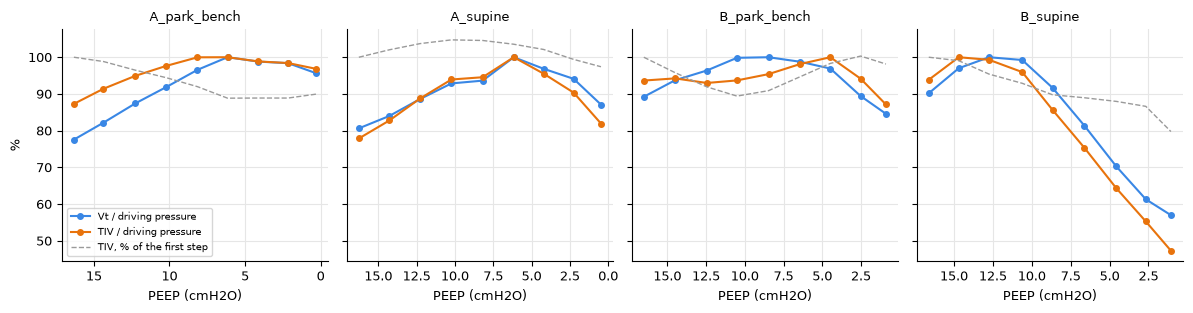

,"compliance (mL/cmH2O), range","best PEEP, Vt / driving","best PEEP, TIV / driving"
trial,,,
A_park_bench,53-68,6.2,6.2
A_supine,69-85,6.2,6.2
B_park_bench,36-43,8.5,4.5
B_supine,24-43,12.7,14.7


In [9]:
steps["driving"] = [trials[t].steps.driving_pressure[k] for t, k in zip(steps.trial, steps.step)]
steps["vt"] = [trials[t].steps.tidal_volume[k] for t, k in zip(steps.trial, steps.step)]
steps["compliance (mL/cmH2O)"] = steps.vt / steps.driving
steps["mL/cmH2O % of best"] = (100 * steps["compliance (mL/cmH2O)"]
                               / steps.groupby("trial")["compliance (mL/cmH2O)"].transform("max"))
steps["TIV % of first step"] = 100 * steps.tiv / steps.groupby("trial").tiv.transform("first")

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (name, t) in zip(axes, steps.groupby("trial")):
    ax.plot(t.peep, t["mL/cmH2O % of best"], "o-", color=BLUE, ms=4, label="Vt / driving pressure")
    ax.plot(t.peep, t["compliance % of best"], "o-", color=ORANGE, ms=4, label="TIV / driving pressure")
    ax.plot(t.peep, t["TIV % of first step"], "--", color=GREY, lw=1, label="TIV, % of the first step")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("PEEP (cmH2O)")
    ax.invert_xaxis()
axes[0].set_ylabel("%")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()


def best_peep(table, column):
    return table.loc[table.groupby("trial")[column].idxmax()].set_index("trial").peep.round(1)


pd.DataFrame({
    "compliance (mL/cmH2O), range": steps.groupby("trial")["compliance (mL/cmH2O)"].agg(
        lambda c: f"{c.min():.0f}-{c.max():.0f}"),
    "best PEEP, Vt / driving": best_peep(steps, "compliance (mL/cmH2O)"),
    "best PEEP, TIV / driving": best_peep(steps, "compliance"),
})

**Result:** global compliance is 53-68 mL/cmH2O in A park bench, 69-85 in A supine, 36-43 in B park bench and 24-43 in
B supine. The two curves have the same shape where compliance changes the most (A supine, B supine down to PEEP 6.6);
they part where it changes little (A park bench at high PEEP; B park bench, best PEEP 8.5 against 4.5 on almost flat
curves) and at the lowest PEEP of B supine (57 against 47 %). The grey line explains it: with the same Vt, the TIV of
the slice changes between steps, down to 89 % in A park bench and 80 % in B supine at PEEP 1, up to 105 % in A supine.
Part of the volume goes to lung outside the slice, or the impedance per mL changes with PEEP.

**Decision:** both compliances are kept: Vt / driving pressure (the respiratory system, in mL/cmH2O) and TIV / driving
pressure (EIT units, which also follows what changes in the slice).

### Regional tidal volume and compliance in mL

The pixels are compartments **in parallel**, all under the same driving pressure, like balloons on the same pressure
source, and compliances in parallel add up. So the compliance of a region is the **sum** of the compliances of its
pixels, not their mean (which would depend on how many pixels the region has): sum of the pixel TIV / driving pressure
= TIV of the region / driving pressure. The regions add up to the whole lung. In mL: share of the region (TIV of the
region / TIV of the lung) x Vt / driving pressure. Ventral and dorsal halves (cut on the vertical extent of the lung),
right and left halves (cut at the midline of the image), median of the analysed breaths of each step:

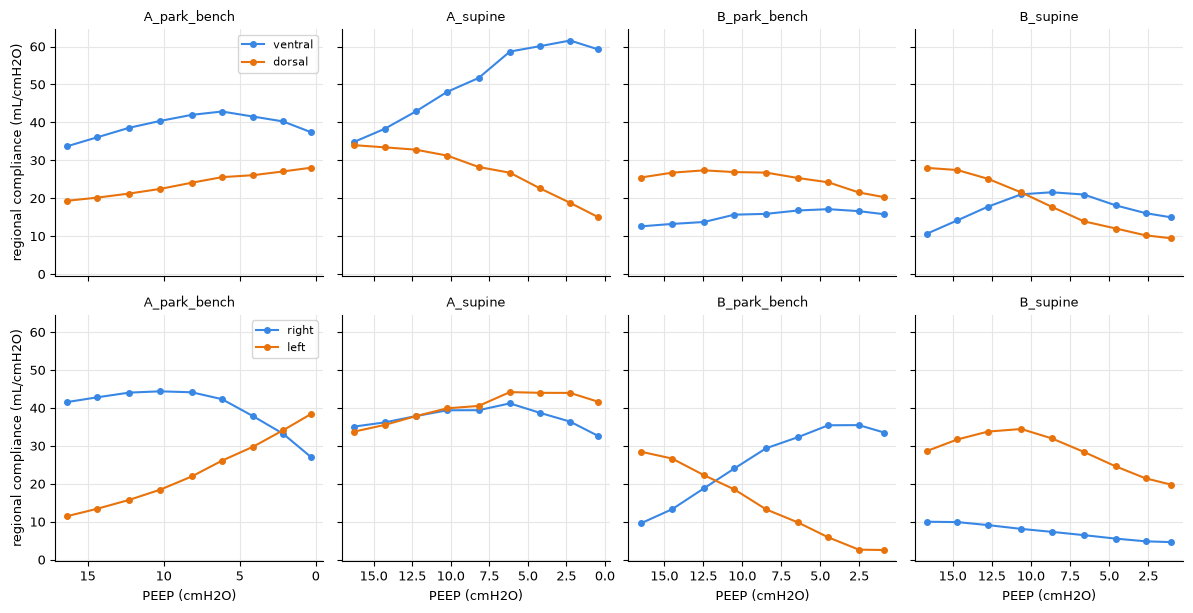

TIV (mL), first - last step best PEEP  \
A_park_bench dorsal                    201 - 236       0.3   
             left                      119 - 323       0.3   
             right                     431 - 227      10.2   
             ventral                   349 - 314       6.2   
A_supine     dorsal                    272 - 112      16.3   
             left                      270 - 308       6.2   
             right                     280 - 242       6.2   
             ventral                   278 - 438       2.3   
B_park_bench dorsal                    268 - 225      12.5   
             left                       299 - 28      16.5   
             right                     101 - 372       2.5   
             ventral                   132 - 175       4.5   
B_supine     dorsal                    289 - 155      16.6   
             left                      297 - 324      10.6   
             right                      103 - 76      16.6   
             ventral                   111 - 245       8.7   

                     best compliance (mL/cmH2O)  
A_park_bench dorsal                        28.1  
             left                          38.4  
             right                         44.4  
             ventral                       42.9  
A_supine     dorsal                        34.0  
             left                          44.2  
             right                         41.2  
             ventral                       61.6  
B_park_bench dorsal                        27.4  
             left                          28.5  
             right                         35.5  
             ventral                       17.1  
B_supine     dorsal                        28.0  
             left                          34.5  
             right                         10.0  
             ventral                       21.6

In [10]:
rows = []
for name, trial in trials.items():
    rec, b, s = trial.recording, trial.breaths, trial.steps
    start, peak = b.start_idx.to_numpy(), b.peak_idx.to_numpy()
    tiv_lung = rec.global_signal[peak] - rec.global_signal[start]
    a, step = b.analysed.to_numpy(), b.peep_step.to_numpy()
    for region in ("ventral", "dorsal", "right", "left"):
        signal = rec.roi_signals[region].to_numpy()
        share = (signal[peak] - signal[start]) / tiv_lung
        for k in range(len(s)):
            share_k = np.median(share[a & (step == k)])
            rows.append({"trial": name, "peep": s.peep[k], "region": region, "share (%)": 100 * share_k,
                         "TIV (mL)": share_k * s.tidal_volume[k],
                         "compliance (mL/cmH2O)": share_k * s.tidal_volume[k] / s.driving_pressure[k]})
regional = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 4, figsize=(12, 6.2), sharey=True, sharex="col")
for row, pair in enumerate([("ventral", "dorsal"), ("right", "left")]):
    for ax, (name, t) in zip(axes[row], regional.groupby("trial")):
        for region, color in zip(pair, (BLUE, ORANGE)):
            r = t[t.region == region]
            ax.plot(r.peep, r["compliance (mL/cmH2O)"], "o-", color=color, ms=4, label=region)
        ax.set_title(name, fontsize=9)
        if row == 0:
            ax.invert_xaxis()
        else:
            ax.set_xlabel("PEEP (cmH2O)")
    axes[row, 0].set_ylabel("regional compliance (mL/cmH2O)")
    axes[row, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

summary = {}
for (name, region), r in regional.groupby(["trial", "region"]):
    summary[(name, region)] = {"TIV (mL), first - last step": f"{r['TIV (mL)'].iloc[0]:.0f} - {r['TIV (mL)'].iloc[-1]:.0f}",
                               "best PEEP": round(r.peep[r["compliance (mL/cmH2O)"].idxmax()], 1),
                               "best compliance (mL/cmH2O)": round(r["compliance (mL/cmH2O)"].max(), 1)}
pd.DataFrame(summary).T

**Result:** supine, as PEEP falls, dorsal compliance falls (A from 34 to 15, B from 28 to 10 mL/cmH2O) and ventral
compliance rises (A from 35 to 62; B from 11 to 21, then down to 15); the two curves cross near PEEP 16 in A (already at
the first step) and near 10.6 in B. In park bench ventral and dorsal do not cross, and in A dorsal compliance rises as
PEEP falls: on the side, ventral/dorsal is not the axis of gravity.

Right/left (second row) shows in park bench the pattern that ventral/dorsal shows supine: one half loses compliance as
PEEP falls and the other gains it. In A park bench the right half falls (44 to 27 mL/cmH2O) and the left rises (12 to
38), crossing near PEEP 2.5; in B park bench the left falls (28 to 3) and the right rises (10 to 35), crossing near
12.5. The half that loses compliance behaves as the dependent lung (right in A, left in B), to be checked against the
side recorded in the case report form. Supine, right and left are close in A; in B the right half has a low
compliance at every step (10 to 5 mL/cmH2O, about 100 mL of the 400). The regions sum to Vt by construction: these mL
are the share of the slice, not independent measurements.

**Decision:** every region is computed; which regions are dependent depends on the position, joined from the clinical
data at the time of the analysis.

## 4. PEEP trials: changes between steps and the Costa method

**Costa method** (Costa et al., Intensive Care Med 2009, DOI: 10.1007/s00134-009-1447-y; formulas as reported by Shono
and Kotani, J Intensive Care 2019, DOI: 10.1186/s40560-019-0358-4):

- compliance of each pixel at each step = median pixel TIV of the analysed breaths / driving pressure of the step;
- each pixel has its best compliance, at its best PEEP;
- at a step with a lower PEEP than its best, the loss of compliance of the pixel, as % of its best, is **collapse**; at
  a higher PEEP it is **overdistension**; the loss is at most 100 % (a pixel that is no more ventilated has a TIV
  around zero, slightly negative with noise, and has lost all of its compliance);
- collapse (and overdistension) of the step = mean of the pixel %, weighted by the best compliance of each pixel, over
  the pixels of the lung mask;
- the crossing of the two curves is the PEEP with the best balance between them.

Check on two synthetic pixels: pixel 1 has its best compliance at PEEP 16 and loses half of it at 6; pixel 2 has its
best at 6 and three times the best compliance of pixel 1.

In [11]:
def costa_from_compliance(pixel_c, peep, valid):
    """Collapse and overdistension % per step from pixel compliance (steps, rows, cols)."""
    best = np.nanmax(pixel_c, axis=0)
    best_step = np.nanargmax(np.where(np.isnan(pixel_c), -np.inf, pixel_c), axis=0)
    valid = valid & (best > 0)
    loss = np.minimum((best - pixel_c) / best * 100, 100)    # % below the best, at most 100
    weight = best[valid].sum()
    collapse, overdistension = [], []
    for k in range(len(peep)):
        below = valid & (peep[k] < peep[best_step])           # lower PEEP than the pixel's best: collapse
        above = valid & (peep[k] > peep[best_step])           # higher PEEP than the pixel's best: overdistension
        collapse.append((loss[k][below] * best[below]).sum() / weight)
        overdistension.append((loss[k][above] * best[above]).sum() / weight)
    return pd.DataFrame({"peep": peep, "collapse": collapse, "overdistension": overdistension})


def crossing(table):
    """PEEP where the collapse and overdistension curves cross (linear interpolation)."""
    t = table.sort_values("peep")
    diff = (t.collapse - t.overdistension).to_numpy()
    for i in range(len(diff) - 1):
        if diff[i] >= 0 >= diff[i + 1]:
            p0, p1 = t.peep.iloc[i], t.peep.iloc[i + 1]
            return p0 + (p1 - p0) * diff[i] / (diff[i] - diff[i + 1])
    return np.nan


peep = np.array([16.0, 6.0])
pixel_c = np.array([[[1.0, 1.5]],                            # PEEP 16: pixel 1 at its best, pixel 2 at half of 3
                    [[0.5, 3.0]]])                           # PEEP 6: pixel 1 at half, pixel 2 at its best
costa_from_compliance(pixel_c, peep, np.ones((1, 2), dtype=bool)).round(1)

,peep,collapse,overdistension
0,16.0,0.0,37.5
1,6.0,12.5,0.0


**Result:** at PEEP 6 pixel 1 lost 50 % (collapse) with weight 1 out of 4: 12.5 %. At PEEP 16 pixel 2 lost 50 %
(overdistension) with weight 3 out of 4: 37.5 %. On the four trials:

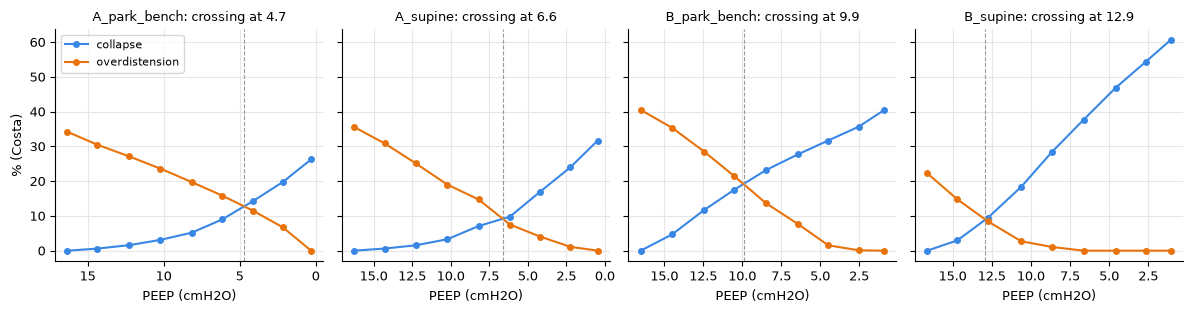

In [12]:
def costa(trial):
    b = trial.breaths
    images = tidal_images(trial.recording)
    a, step = b.analysed.to_numpy(), b.peep_step.to_numpy()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)       # pixels outside the mask are all NaN
        pixel_c = np.array([np.nanmedian(images[a & (step == k)], axis=0) / trial.steps.driving_pressure[k]
                            for k in range(len(trial.steps))])
        return costa_from_compliance(pixel_c, trial.steps.peep.to_numpy(), trial.recording.lung_mask)


odcl = {name: costa(trial) for name, trial in trials.items()}
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (name, table) in zip(axes, odcl.items()):
    ax.plot(table.peep, table.collapse, "o-", color=BLUE, ms=4, label="collapse")
    ax.plot(table.peep, table.overdistension, "o-", color=ORANGE, ms=4, label="overdistension")
    cross = crossing(table)
    ax.axvline(cross, color=GREY, lw=0.8, ls="--")
    ax.set_title(f"{name}: crossing at {cross:.1f}", fontsize=9)
    ax.set_xlabel("PEEP (cmH2O)")
    ax.invert_xaxis()
axes[0].set_ylabel("% (Costa)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [13]:
best_peep = steps.loc[steps.groupby("trial").compliance.idxmax(), ["trial", "peep"]].set_index("trial").peep
pd.DataFrame({"crossing PEEP": {n: crossing(t) for n, t in odcl.items()},
              "PEEP of the best global compliance": best_peep}).round(1)

,crossing PEEP,PEEP of the best global compliance
A_park_bench,4.7,6.2
A_supine,6.6,6.2
B_park_bench,9.9,4.5
B_supine,12.9,14.7


**Result:** overdistension falls and collapse rises as PEEP is lowered. The crossings are 4.7 and 6.6 cmH2O in
patient A, 9.9 and 12.9 in patient B; in both patients the crossing is lower in park bench than supine (an observation
on two patients). The crossing is within 2 cmH2O of the PEEP of the best global compliance in three trials (A park
bench 4.7 and 6.2, A supine 6.6 and 6.2, B supine 12.9 and 14.7); not in B park bench, where compliance changes little
across the steps (87-100 %): 9.9 and 4.5.

### Changes between steps

Statistics across patients need numbers on a common scale. EELI in arbitrary units is not, so its change is expressed
**in tidal volumes**: the change of EELI divided by the TIV of the reference step (the previous step, or the first one
for the cumulative change). Compliance as % of its best, collapse and overdistension in %.

In [14]:
rows = []
for name, trial in trials.items():
    b, s = trial.breaths, trial.steps
    eeli = trial.recording.global_signal[b.start_idx.to_numpy()]
    tiv = np.nansum(tidal_images(trial.recording), axis=(1, 2))
    a, step = b.analysed.to_numpy(), b.peep_step.to_numpy()
    eeli_step = np.array([np.median(eeli[a & (step == k)]) for k in range(len(s))])
    tiv_step = np.array([np.median(tiv[a & (step == k)]) for k in range(len(s))])
    best = steps.query("trial == @name")["compliance % of best"].to_numpy()
    vt = s.tidal_volume.to_numpy()
    table = odcl[name]
    for k in range(1, len(s)):
        rows.append({"trial": name, "peep": round(s.peep[k], 1),
                     "dEELI in TIV (vs previous)": (eeli_step[k] - eeli_step[k - 1]) / tiv_step[k - 1],
                     "dEELI in TIV (vs first)": (eeli_step[k] - eeli_step[0]) / tiv_step[0],
                     "dEELI in mL (vs previous)": (eeli_step[k] - eeli_step[k - 1]) / tiv_step[k - 1] * vt[k - 1],
                     "dEELI in mL (vs first)": (eeli_step[k] - eeli_step[0]) / tiv_step[0] * vt[0],
                     "d compliance (% of best)": best[k] - best[k - 1],
                     "d collapse (%)": table.collapse[k] - table.collapse[k - 1],
                     "d overdistension (%)": table.overdistension[k] - table.overdistension[k - 1]})
deltas = pd.DataFrame(rows)
deltas.groupby("trial")[["dEELI in TIV (vs previous)", "dEELI in TIV (vs first)", "d compliance (% of best)",
                          "d collapse (%)", "d overdistension (%)"]].agg(["min", "max"]).round(2)

dEELI in TIV (vs previous)       dEELI in TIV (vs first)        \
                                    min   max                     min   max   
trial                                                                         
A_park_bench                      -0.59 -0.29                   -3.15 -0.29   
A_supine                          -0.63 -0.41                   -4.40 -0.41   
B_park_bench                      -0.64 -0.20                   -3.60 -0.20   
B_supine                          -0.47 -0.02                   -2.28 -0.35   

             d compliance (% of best)       d collapse (%)        \
                                  min   max            min   max   
trial                                                              
A_park_bench                    -1.57  4.11           0.59  6.45   
A_supine                        -8.41  6.01           0.62  7.73   
B_park_bench                    -7.02  2.75           3.97  7.00   
B_supine                       -11.00  6.14           2.97  9.96   

             d overdistension (%)        
                              min   max  
trial                                    
A_park_bench                -6.70 -3.41  
A_supine                    -7.20 -1.12  
B_park_bench                -7.81 -0.11  
B_supine                    -7.50  0.00

**Result:** each step (2 mbar on the ventilator) lowers EELI by 0.02-0.64 tidal volumes; by the last step the
cumulative loss is 2.3-4.4 tidal volumes. Per step, compliance changes by -11 to +6 % of its best, collapse rises by
0.6-10 % and overdistension falls by 0-8 %. These numbers can go into the same analysis for different patients if their
trials test the same PEEP range and steps (% of the best step and Costa are relative to the range tested).

### The change of EELI in mL

EELI itself stays in arbitrary units; its change becomes mL with the tidal volume (change in tidal volumes x Vt of the
same reference step). A check that does not use EIT: the volume lost from the first to the last step predicted by the
compliance of the steps, the sum of compliance x change of PEEP between steps (it sees only the tidal compliance, not
alveoli that close).

In [15]:
rows = []
for name, trial in trials.items():
    s, d = trial.steps, deltas[deltas.trial == name]
    c = (s.tidal_volume / s.driving_pressure).to_numpy()
    rows.append({"trial": name,
                 "EIT, vs first step (mL)": d["dEELI in mL (vs first)"].iloc[-1],
                 "EIT, sum of the steps vs previous (mL)": d["dEELI in mL (vs previous)"].sum(),
                 "compliance x change of PEEP (mL)": np.sum((c[1:] + c[:-1]) / 2 * np.diff(s.peep.to_numpy()))})
eelv = pd.DataFrame(rows).set_index("trial")
eelv["ratio EIT / compliance"] = eelv["EIT, vs first step (mL)"] / eelv["compliance x change of PEEP (mL)"]
eelv.round(1)

,"EIT, vs first step (mL)","EIT, sum of the steps vs previous (mL)",compliance x change of PEEP (mL),ratio EIT / compliance
trial,,,,
A_park_bench,-1733.8,-1867.3,-1016.1,1.7
A_supine,-2419.4,-2356.0,-1238.1,2.0
B_park_bench,-1441.5,-1524.4,-636.5,2.3
B_supine,-910.1,-969.6,-567.9,1.6


**Result:** from the first to the last step EIT estimates a loss of 0.9-2.4 L (the two reference steps agree within
8 %), 1.6-2.3 times the 0.6-1.2 L predicted by compliance x change of PEEP. The difference can come from alveoli that
close at low PEEP (missed by the compliance estimate, which would then be too low) or from the assumption of the EIT
conversion (the same impedance per mL for the tidal and the end-expiratory change, not guaranteed in a dependent lung
that closes, so EIT would be too high). Without a reference measurement of lung volume (e.g. nitrogen washout) these
recordings cannot tell which.

**Decision:** the change of EELI is given in tidal volumes (what EIT measures) and in mL (an exploratory estimate).

### The same with fastEIT

The indices of this notebook are implemented in `fasteit.features` (`tidal_features`, `peep_trial_features`). On the
four trials they give the same crossing, best PEEP and change of EELI as the prototypes above:

In [16]:
from fasteit.features import peep_trial_features

rows = []
for name, trial in trials.items():
    features = peep_trial_features(trial)
    summary, last = features.summary.iloc[0], features.steps.iloc[-1]
    rows.append({"trial": name,
                 "crossing PEEP": (summary.crossing_peep, crossing(odcl[name])),
                 "best PEEP, Vt / driving": (summary.best_peep_compliance_ml, steps.peep[
                     steps[steps.trial == name]["compliance (mL/cmH2O)"].idxmax()]),
                 "dEELI in mL, last vs first": (last.d_eeli_ml_vs_first,
                                                deltas[deltas.trial == name]["dEELI in mL (vs first)"].iloc[-1])})
pd.DataFrame(rows).set_index("trial").map(lambda pair: f"{pair[0]:.1f} / {pair[1]:.1f}").rename_axis(
    "fastEIT / notebook", axis=1)

fastEIT / notebook,crossing PEEP,"best PEEP, Vt / driving","dEELI in mL, last vs first"
trial,,,
A_park_bench,4.7 / 4.7,6.2 / 6.2,-1733.8 / -1733.8
A_supine,6.6 / 6.6,6.2 / 6.2,-2419.4 / -2419.4
B_park_bench,9.9 / 9.9,8.5 / 8.5,-1441.5 / -1441.5
B_supine,12.9 / 12.9,12.7 / 12.7,-910.1 / -910.1


## 5. Decisions

| § | Decision | fastEIT |
|---|----------|---------|
| 1 | EELI = in-mask signal at the start of the breath; TIV = peak - start; one sample at the layer 2 frames | columns `eeli`, `tiv` of `tidal_features()` and `peep_trial_features()` |
| 2 | Share by region (ratio of sums), GI over the lung pixels, centre of ventilation on the image grid (0 = ventral / patient right) | `features.breath_indices.global_inhomogeneity`, `centre_of_ventilation`; `regions.share` |
| 3 | Compliance = TIV / driving pressure (EIT units) and Vt / driving pressure (mL/cmH2O), both kept; per step from the median TIV and the driving pressure of the step | columns `compliance`, `compliance_ml` |
| 3 | Region: TIV, compliance (sum of its pixels) and, with Vt, `tiv_ml` and `compliance_ml` (share x Vt); every region computed | `regions`, `step_regions` |
| 4 | Costa collapse and overdistension, loss at most 100 %, crossing PEEP | `features.costa.collapse_and_overdistension`, `crossing_peep` |
| 4 | Changes vs the previous and the first step: EELI in tidal volumes and in mL, compliance in % of the best, collapse, overdistension | columns `d_*` of `PeepTrialFeatures.steps` |
| - | Tidal recordings: median and quartiles over the valid breaths | `TidalFeatures.summary` |
| 3 | Tidal volume: typed for each step, typed for the recording (when constant, as in volume control), or measured, in this order | `segment_peep_trial(tidal_volumes=...)`, `RecordingContext.tidal_volume_ml`, column `tidal_volume_used` |

Assumptions of the values in mL:

- compliance from the airway pressure is that of the respiratory system, not of the lung, and the same driving pressure
  is used for every region;
- the volume of a region is the global tidal volume apportioned by the share of the imaged slice: the regions sum to
  Vt, so it is a distribution, not an independent measurement; it is not corrected for the uneven sensitivity of EIT,
  for a different impedance per mL in diseased regions, or for the lung outside the slice;
- the change of EELI follows the change of end-expiratory lung volume linearly during PEEP changes (Hinz et al.,
  Intensive Care Med 2003, DOI: 10.1007/s00134-002-1555-4); its conversion to mL further assumes the same impedance per
  mL for the tidal and the end-expiratory change, in all regions and at every PEEP.

Limits: two patients, decremental trials only; Costa implemented from its published formulas and checked on synthetic
pixels, not against another implementation; tidal volume as set on the ventilator (550 and 400 mL), not measured; one
lung mask for the whole trial (pixels ventilated at some step but outside it carry at most 1-3 % of the TIV).